# ==============================================================================
# BÀI TẬP 1: MASKED AUTOENCODER FOR DISTRIBUTION ESTIMATION (MADE)
# ==============================================================================

### 🎯 Mục tiêu bài học:
1. **Chuyển hóa MLP thành Mô hình Tự hồi quy (Autoregressive):**
   * Phân rã xác suất đồng thời theo Quy tắc chuỗi (Chain Rule): $p(x) = \prod_{d=1}^D p(x_{o_d} \mid x_{o_{<d}})$.
   * Khắc phục nhược điểm rò rỉ thông tin trong mạng Autoencoder thông thường bằng kỹ thuật gán bậc nơ-ron (Ordering Degrees) và ma trận mặt nạ nhị phân trên trọng số.
2. **Cài đặt lớp `MaskedLinear`:**
   * Tầng ẩn: $M_{j,i} = \mathbf{1}_{m_j^l \ge m_i^{l-1}}$ (truyền thông tin từ các đặc trưng quá khứ).
   * Tầng ra: $M_{j,i} = \mathbf{1}_{d_j > m_i^L}$ (bảo toàn điều kiện chặt chẽ: biến $x_i$ chỉ phụ thuộc vào các biến có thứ tự đứng trước, không nhìn thấy chính nó!).
3. **Đánh giá Log-Likelihood chính xác:** Đo lường NLL trên tập kiểm thử bằng đơn vị **nats** và **bits/dim**.
4. **Sinh mẫu tuần tự (Autoregressive Sampling):** Sinh ảnh mới từ canvas rỗng bằng cách duyệt tuần tự theo thứ tự bậc từ $1 \to D$.

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# Thiết lập seed cố định
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Thiết bị thực thi: {device}")

[+] Thiết bị thực thi: cuda


In [2]:
# ==============================================================================
# 1. CHUẨN BỊ TẬP DỮ LIỆU BINARIZED MNIST (784 CHIỀU)
# Mỗi pixel được ngưỡng hóa nhị phân {0.0, 1.0}
# ==============================================================================
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: (x > 0.5).float().view(-1)) # Binarize & Flatten -> 784
])

train_dataset = datasets.MNIST(root="./data", train=True, download=False, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=False, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"[+] Dữ liệu huấn luyện: {len(train_dataset):,} ảnh nhị phân 784 chiều")
print(f"[+] Dữ liệu kiểm thử:   {len(test_dataset):,} ảnh nhị phân 784 chiều")

[+] Dữ liệu huấn luyện: 60,000 ảnh nhị phân 784 chiều
[+] Dữ liệu kiểm thử:   10,000 ảnh nhị phân 784 chiều


In [3]:
# ==============================================================================
# 2. CÀI ĐẶT LỚP MASKEDLINEAR VÀ MÔ HÌNH MADE
# ==============================================================================

class MaskedLinear(nn.Linear):
    """
    Tầng Linear được nhân với ma trận mặt nạ nhị phân M:
    y = x (W * M)^T + b
    """
    def __init__(self, in_features, out_features, bias=True):
        super().__init__(in_features, out_features, bias=bias)
        self.register_buffer('mask', torch.ones(out_features, in_features))

    def set_mask(self, mask):
        self.mask.data.copy_(torch.from_numpy(mask.astype(np.float32)))

    def forward(self, x):
        return F.linear(x, self.weight * self.mask, self.bias)


class MADE(nn.Module):
    """
    Masked Autoencoder for Distribution Estimation (Germain et al., 2015)
    """
    def __init__(self, nin=784, hidden_dims=[512, 512], nout=784, random_order=False):
        super().__init__()
        self.nin = nin
        self.nout = nout
        self.hidden_dims = hidden_dims
        self.random_order = random_order
        
        # Khởi tạo các tầng MaskedLinear
        self.net = []
        hs = [nin] + hidden_dims + [nout]
        for h0, h1 in zip(hs[:-1], hs[1:]):
            self.net.extend([
                MaskedLinear(h0, h1),
                nn.ReLU(inplace=True)
            ])
        self.net.pop() # Bỏ ReLU ở tầng ra cùng
        self.net = nn.Sequential(*self.net)
        
        # Tạo thứ tự bậc (Ordering Degrees) và mặt nạ kết nối
        self.create_masks()

    def create_masks(self):
        L = len(self.hidden_dims)
        
        # 1. Bậc của tầng vào: hoán vị thứ tự từ 1 đến D
        if self.random_order:
            self.m = [np.random.permutation(self.nin) + 1]
        else:
            self.m = [np.arange(1, self.nin + 1)] # Thứ tự tự nhiên 1 -> 784
        
        # 2. Bậc của các tầng ẩn: gán ngẫu nhiên m^l in {1, ..., D - 1}
        for l in range(L):
            # Lấy cận dưới là min bậc tầng trước để tránh nơ-ron cô lập
            min_deg = np.min(self.m[-1])
            self.m.append(np.random.randint(min_deg, self.nin, size=self.hidden_dims[l]))
            
        # 3. Tạo ma trận mặt nạ cho từng tầng
        masks = []
        # Tầng ẩn: M_{j, i} = 1_{m_j^l >= m_i^{l-1}}
        for l in range(L):
            mask = (self.m[l+1][:, None] >= self.m[l][None, :]).astype(np.float32)
            masks.append(mask)
            
        # Tầng ra: M_{j, i} = 1_{d_j > m_i^L} (Bảo toàn strictly autoregressive!)
        mask_out = (self.m[0][:, None] > self.m[-1][None, :]).astype(np.float32)
        masks.append(mask_out)
        
        # Gán mặt nạ vào từng lớp MaskedLinear
        layers = [l for l in self.net if isinstance(l, MaskedLinear)]
        for l, m in zip(layers, masks):
            l.set_mask(m)

    def forward(self, x):
        return self.net(x)

# Khởi tạo mô hình
model = MADE(nin=784, hidden_dims=[512, 512], nout=784).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(f"[+] Đã khởi tạo MADE với 2 tầng ẩn [512, 512] và gán bậc thành công!")

[+] Đã khởi tạo MADE với 2 tầng ẩn [512, 512] và gán bậc thành công!


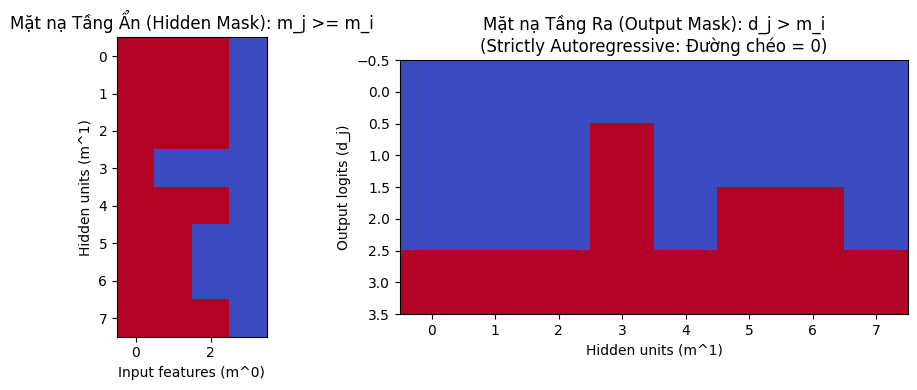

In [4]:
# ==============================================================================
# 3. TRỰC QUAN HÓA MA TRẬN MẶT NẠ NHỊ PHÂN TRỌNG SỐ (SANITY CHECK)
# Kiểm tra một mạng Toy MADE nhỏ (4 -> 8 -> 4) để quan sát tính nhân quả tam giác
# ==============================================================================
toy_made = MADE(nin=4, hidden_dims=[8], nout=4, random_order=False)
toy_layers = [l for l in toy_made.net if isinstance(l, MaskedLinear)]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

m_hidden = toy_layers[0].mask.cpu().numpy()
axes[0].imshow(m_hidden, cmap='coolwarm', vmin=0, vmax=1)
axes[0].set_title("Mặt nạ Tầng Ẩn (Hidden Mask): m_j >= m_i")
axes[0].set_xlabel("Input features (m^0)")
axes[0].set_ylabel("Hidden units (m^1)")

m_out = toy_layers[1].mask.cpu().numpy()
axes[1].imshow(m_out, cmap='coolwarm', vmin=0, vmax=1)
axes[1].set_title("Mặt nạ Tầng Ra (Output Mask): d_j > m_i\n(Strictly Autoregressive: Đường chéo = 0)")
axes[1].set_xlabel("Hidden units (m^1)")
axes[1].set_ylabel("Output logits (d_j)")

plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# 4. HUẤN LUYỆN MADE & ĐÁNH GIÁ ĐỊNH LƯỢNG (NATS VÀ BITS/DIM)
# ==============================================================================

def evaluate_nll(model, loader):
    model.eval()
    total_loss_nats = 0.0
    total_samples = 0
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            logits = model(x)
            # BCEWithLogitsLoss tính NLL cho mỗi pixel rồi cộng trên 784 chiều
            loss = F.binary_cross_entropy_with_logits(logits, x, reduction='none').sum(dim=1)
            total_loss_nats += loss.sum().item()
            total_samples += x.size(0)
            
    mean_nats_per_image = total_loss_nats / total_samples
    # Chuyển đổi sang bits/dim: nats / (784 * ln(2))
    bits_per_dim = mean_nats_per_image / (784.0 * np.log(2.0))
    return mean_nats_per_image, bits_per_dim

EPOCHS = 10
train_nats_history, test_nats_history = [], []
test_bpd_history = []

print("=" * 70)
print("TIẾN HÀNH HUẤN LUYỆN MÔ HÌNH MADE TRÊN BINARIZED MNIST (10 EPOCHS)")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_train_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = F.binary_cross_entropy_with_logits(logits, x, reduction='none').sum(dim=1).mean()
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * x.size(0)
        
    train_nats = total_train_loss / len(train_dataset)
    test_nats, test_bpd = evaluate_nll(model, test_loader)
    
    train_nats_history.append(train_nats)
    test_nats_history.append(test_nats)
    test_bpd_history.append(test_bpd)
    
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train NLL: {train_nats:6.2f} nats | "
          f"Test NLL: {test_nats:6.2f} nats | Test BPD: {test_bpd:.4f} bits/dim")

print("[+] Huấn luyện và đánh giá hoàn tất!")

TIẾN HÀNH HUẤN LUYỆN MÔ HÌNH MADE TRÊN BINARIZED MNIST (10 EPOCHS)


Epoch [01/10] | Train NLL: 215.28 nats | Test NLL: 156.53 nats | Test BPD: 0.2880 bits/dim


Epoch [02/10] | Train NLL: 141.01 nats | Test NLL: 127.92 nats | Test BPD: 0.2354 bits/dim


Epoch [03/10] | Train NLL: 121.45 nats | Test NLL: 114.21 nats | Test BPD: 0.2102 bits/dim


Epoch [04/10] | Train NLL: 111.31 nats | Test NLL: 106.55 nats | Test BPD: 0.1961 bits/dim


...

Epoch [06/10] | Train NLL: 101.22 nats | Test NLL:  99.14 nats | Test BPD: 0.1824 bits/dim


Epoch [07/10] | Train NLL:  98.44 nats | Test NLL:  96.96 nats | Test BPD: 0.1784 bits/dim


Epoch [08/10] | Train NLL:  96.41 nats | Test NLL:  95.65 nats | Test BPD: 0.1760 bits/dim


Epoch [09/10] | Train NLL:  94.84 nats | Test NLL:  94.18 nats | Test BPD: 0.1733 bits/dim


Epoch [10/10] | Train NLL:  93.56 nats | Test NLL:  93.16 nats | Test BPD: 0.1714 bits/dim
[+] Huấn luyện và đánh giá hoàn tất!


[+] Bắt đầu lấy mẫu tuần tự cho 64 ảnh qua 784 lượt forward...


[+] Hoàn tất sinh mẫu trong: 0.42 giây!


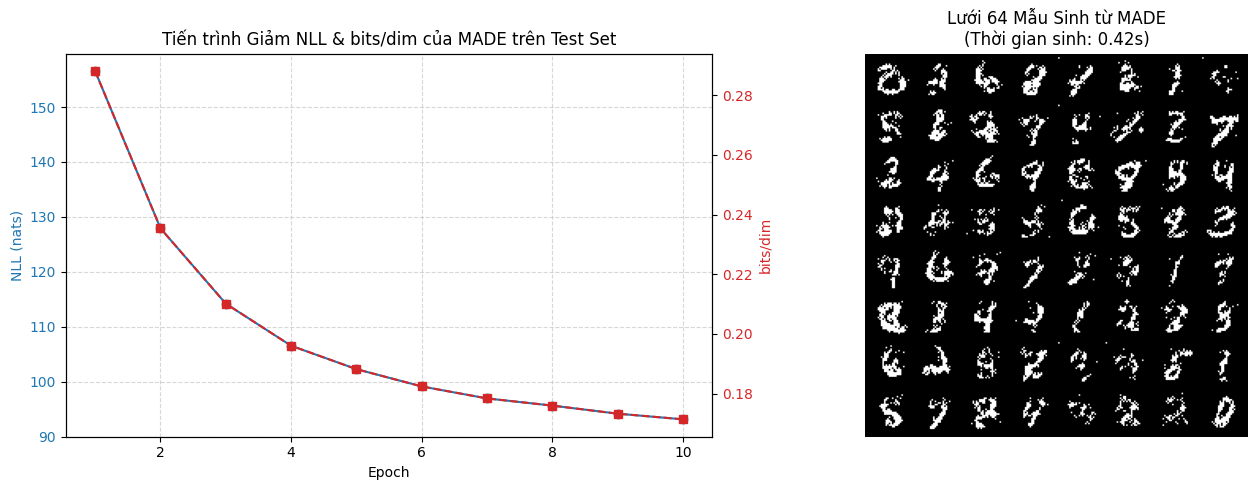

In [6]:
# ==============================================================================
# 5. LẤY MẪU TỰ HỒI QUY (AUTOREGRESSIVE SAMPLING)
# Suy luận tuần tự từng biến theo thứ tự bậc từ 1 đến D = 784
# ==============================================================================

def sample_made(model, num_samples=64):
    model.eval()
    samples = torch.zeros((num_samples, model.nin), device=device)
    
    start_time = time.time()
    print(f"[+] Bắt đầu lấy mẫu tuần tự cho {num_samples} ảnh qua 784 lượt forward...")
    
    # Thứ tự lấy mẫu tương ứng với thứ tự bậc m[0]
    # Với thứ tự tự nhiên: d = 1 -> 784 (tương ứng index 0 -> 783)
    order = np.argsort(model.m[0])
    
    with torch.no_grad():
        for i in order:
            logits = model(samples)
            probs = torch.sigmoid(logits[:, i])
            samples[:, i] = torch.bernoulli(probs)
            
    duration = time.time() - start_time
    print(f"[+] Hoàn tất sinh mẫu trong: {duration:.2f} giây!")
    return samples.cpu().view(-1, 1, 28, 28), duration

made_samples, sample_duration = sample_made(model, num_samples=64)

# Trực quan hóa đồ thị hội tụ và lưới ảnh sinh
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị NLL & bits/dim
axes[0].plot(range(1, EPOCHS + 1), test_nats_history, marker='o', label='Test NLL (nats/image)', color='tab:blue')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("NLL (nats)", color='tab:blue')
axes[0].tick_params(axis='y', labelcolor='tab:blue')
axes[0].grid(True, linestyle="--", alpha=0.5)

ax2 = axes[0].twinx()
ax2.plot(range(1, EPOCHS + 1), test_bpd_history, marker='s', label='Test bits/dim', color='tab:red', linestyle='--')
ax2.set_ylabel("bits/dim", color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
axes[0].set_title("Tiến trình Giảm NLL & bits/dim của MADE trên Test Set", fontsize=12)

# Lưới ảnh sinh ra
grid = make_grid(made_samples, nrow=8, padding=2)
axes[1].imshow(grid.permute(1, 2, 0).numpy(), cmap='gray')
axes[1].set_title(f"Lưới 64 Mẫu Sinh từ MADE\n(Thời gian sinh: {sample_duration:.2f}s)", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# ==============================================================================
# 6. BÁO CÁO PHÂN TÍCH VỀ CƠ CHẾ AUTOREGRESSIVE TRONG MADE
# ==============================================================================

### 1. Ý nghĩa của đơn vị nats và bits/dim:
* **nats (natural units):** Được tính bằng tổng Binary Cross-Entropy tự nhiên trên toàn bộ $D = 784$ pixel: $\text{NLL}_{nats} = -\sum_{i=1}^{784} \ln p(x_i \mid x_{<i})$. Giá trị càng nhỏ thể hiện mô hình gán xác suất cao hơn cho ảnh thực tế.
* **bits/dim (bits per dimension):** Là chuẩn đo lường quốc tế cho các mô hình tạo sinh dạng khả dĩ (Likelihood-based models):
$$\text{bits/dim} = \frac{\text{NLL}_{nats}}{D \cdot \ln 2}$$
* Giá trị bits/dim phản ánh số lượng bit tối thiểu theo lý thuyết nén thông tin của Shannon cần thiết để nén một pixel mà không làm mất thông tin.

### 2. So sánh MADE với PixelCNN:
* **MADE (Masked Autoencoder):** Sử dụng các tầng Linear với mặt nạ nhị phân dựa trên bậc nơ-ron. Cực kỳ linh hoạt với dữ liệu vector/bảng (tabular data), cho phép hoán vị bất kỳ thứ tự biến nào (order agnostic).
* **PixelCNN:** Sử dụng Masked Convolution 2D khai thác cấu trúc không gian và tính bất biến tịnh tiến (translation equivariance) của ảnh 2D, thích hợp hơn cho ảnh độ phân giải lớn.

### 3. Đánh giá tốc độ lấy mẫu:
* Quá trình huấn luyện cực kỳ nhanh do toàn bộ 784 pixel được tối ưu hóa song song trong 1 lượt forward duy nhất.
* Quá trình lấy mẫu bị nghẽn tuần tự $O(D) = 784$ lượt forward vì phải sinh từng pixel một theo đúng chuỗi điều kiện xác suất.